# Bankruptcy Prediction — MF815 Machine Learning
## EDA v2: Sentinel Value–Aware Analysis

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

sns.set_theme(style='whitegrid')
print("Libraries loaded.")

Libraries loaded.


## Cell 2 — Load Data

In [22]:
train_raw = pd.read_csv('train.csv')
test_raw  = pd.read_csv('test.csv')

# Drop the row-index column if present
for df in [train_raw, test_raw]:
    unnamed = [c for c in df.columns if c.lower().startswith('unnamed')]
    if unnamed:
        df.drop(columns=unnamed, inplace=True)

print(f"Train shape: {train_raw.shape}  |  Test shape: {test_raw.shape}")
print(f"\nTarget: {'Bankrupt?' in train_raw.columns}")
print(f"\nColumn names (first 10): {train_raw.columns[:10].tolist()}")
print(f"\nTarget distribution:\n{train_raw['Bankrupt?'].value_counts()}")

Train shape: (5455, 96)  |  Test shape: (1364, 95)

Target: True

Column names (first 10): [' ROA(C) before interest and depreciation before interest', ' ROA(A) before interest and % after tax', ' ROA(B) before interest and depreciation after tax', ' Operating Gross Margin', ' Realized Sales Gross Margin', ' Operating Profit Rate', ' Pre-tax net Interest Rate', ' After-tax net Interest Rate', ' Non-industry income and expenditure/revenue', ' Continuous interest rate (after tax)']

Target distribution:
Bankrupt?
0    5285
1     170
Name: count, dtype: int64


## Cell 3 — Target Variable Distribution

=== Target Distribution ===
  Class 0: 5,285  (96.88%)
  Class 1: 170  (3.12%)


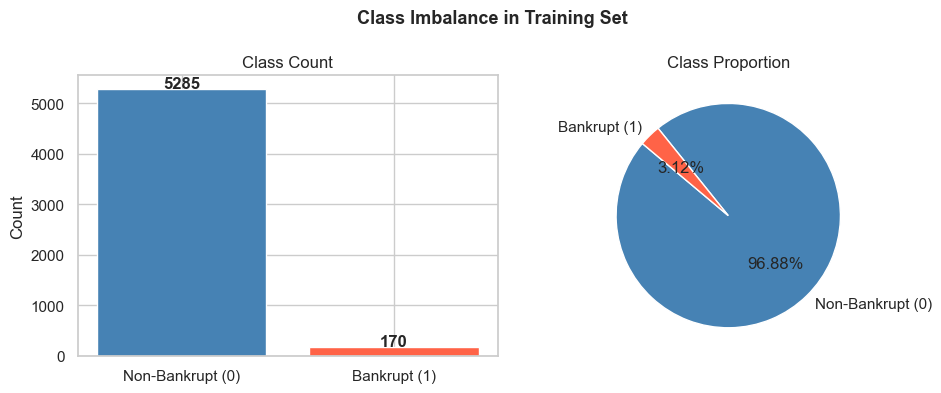


Imbalance ratio (0:1) ≈ 31.1:1  →  SMOTE or class_weight needed


In [23]:
counts = train_raw['Bankrupt?'].value_counts()
pct    = train_raw['Bankrupt?'].value_counts(normalize=True) * 100

print("=== Target Distribution ===")
for cls in [0, 1]:
    print(f"  Class {cls}: {counts[cls]:,}  ({pct[cls]:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Bar chart
axes[0].bar(['Non-Bankrupt (0)', 'Bankrupt (1)'], counts.values,
            color=['steelblue', 'tomato'], edgecolor='white')
axes[0].set_title('Class Count')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(counts.values, labels=['Non-Bankrupt (0)', 'Bankrupt (1)'],
            autopct='%1.2f%%', colors=['steelblue', 'tomato'],
            startangle=140, wedgeprops=dict(edgecolor='white'))
axes[1].set_title('Class Proportion')

plt.suptitle('Class Imbalance in Training Set', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

imbalance_ratio = counts[0] / counts[1]
print(f"\nImbalance ratio (0:1) ≈ {imbalance_ratio:.1f}:1  →  SMOTE or class_weight needed")

## Cell 4 — Sentinel Value Detection

Columns with sentinel values (>= 1e9): 21 / 95

Top 20 by sentinel count:
                                       count  pct(%)
Total Asset Growth Rate                 4356   79.85
Cash Turnover Rate                      2759   50.58
Research and development expense rate   2387   43.76
Inventory Turnover Rate (times)         1810   33.18
Quick Asset Turnover Rate               1732   31.75
Operating Expense Rate                  1670   30.61
Current Asset Turnover Rate              875   16.04
Fixed Assets Turnover Frequency          851   15.60
Long-term Liability to Current Assets     59    1.08
Inventory/Current Liability               53    0.97
Cash/Current Liability                    31    0.57
Total assets to GNP price                 17    0.31
Accounts Receivable Turnover              11    0.20
Average Collection Days                   10    0.18
Allocation rate per person                 9    0.16
Quick Ratio                                6    0.11
Total debt/Total net wort

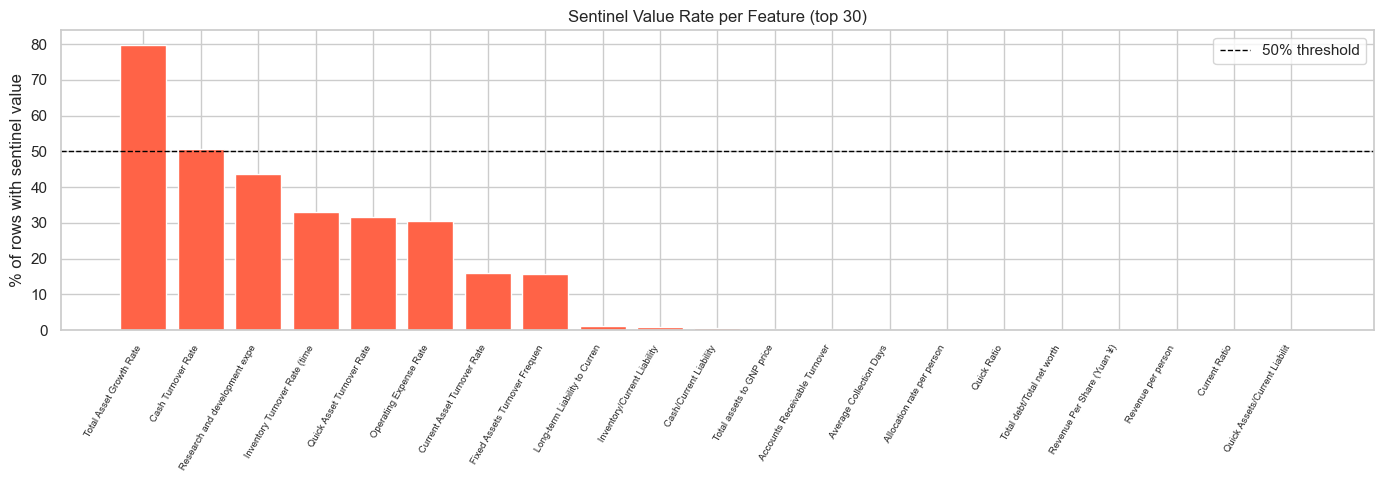

In [24]:
# Financial ratios should not exceed ~100x; values >= 1e9 are placeholder/sentinel
SENTINEL_THRESHOLD = 1e9

features_raw = [c for c in train_raw.columns if c != 'Bankrupt?']
num_features  = train_raw[features_raw].select_dtypes(include=[np.number]).columns.tolist()

# Count sentinel entries per column
sentinel_counts = {}
for col in num_features:
    n = (train_raw[col] >= SENTINEL_THRESHOLD).sum()
    if n > 0:
        sentinel_counts[col] = n

sentinel_series = pd.Series(sentinel_counts).sort_values(ascending=False)
sentinel_pct    = (sentinel_series / len(train_raw) * 100).round(2)

print(f"Columns with sentinel values (>= 1e9): {len(sentinel_series)} / {len(num_features)}")
print(f"\nTop 20 by sentinel count:")
summary = pd.DataFrame({'count': sentinel_series, 'pct(%)': sentinel_pct}).head(20)
print(summary.to_string())

# Compare raw mean vs median to expose scale distortion
print("\nScale distortion check — columns where mean >> 100× median:")
distorted = []
for col in num_features:
    med = train_raw[col].median()
    mean = train_raw[col].mean()
    if med != 0 and abs(mean / med) > 100:
        distorted.append((col, round(mean, 2), round(med, 6)))
    elif med == 0 and mean > 1e6:
        distorted.append((col, round(mean, 2), med))
dist_df = pd.DataFrame(distorted, columns=['Feature', 'Mean', 'Median']).sort_values('Mean', ascending=False)
print(dist_df.to_string(index=False))

# Bar chart of sentinel rates
fig, ax = plt.subplots(figsize=(14, 5))
top30 = sentinel_pct.head(30)
ax.bar(range(len(top30)), top30.values, color='tomato', edgecolor='white')
ax.set_xticks(range(len(top30)))
ax.set_xticklabels([c[:30] for c in top30.index], rotation=60, ha='right', fontsize=7)
ax.axhline(50, color='black', linestyle='--', linewidth=1, label='50% threshold')
ax.set_title('Sentinel Value Rate per Feature (top 30)', fontsize=12)
ax.set_ylabel('% of rows with sentinel value')
ax.legend()
plt.tight_layout()
plt.show()

## Cell 5 — Data Cleaning: Sentinel Replacement + Drop Useless Columns

In [25]:
train = train_raw.copy()
test  = test_raw.copy()

# Step 1: Replace sentinel values with NaN
for col in num_features:
    mask_tr = train[col] >= SENTINEL_THRESHOLD
    mask_te = test[col] >= SENTINEL_THRESHOLD if col in test.columns else None
    train.loc[mask_tr, col] = np.nan
    if mask_te is not None:
        test.loc[mask_te, col] = np.nan

print("Sentinel → NaN replacement done.")

# Step 2: Recheck missing rates after replacement
features = [c for c in train.columns if c != 'Bankrupt?']
miss_rate = train[features].isnull().mean().sort_values(ascending=False)
miss_nonzero = miss_rate[miss_rate > 0]
print(f"\nAfter sentinel replacement — columns with missing: {len(miss_nonzero)} / {len(features)}")
print(f"\nTop 20 by missing rate:")
print(miss_nonzero.head(20).to_string())

# Step 3: Drop columns >50% missing (true missingness after sentinel removal)
DROP_MISS_THRESHOLD = 0.50
cols_drop_miss = miss_rate[miss_rate > DROP_MISS_THRESHOLD].index.tolist()
print(f"\nDrop (>50% missing): {len(cols_drop_miss)}")
print(cols_drop_miss)

# Step 4: Drop zero-variance columns (computed AFTER sentinel removal)
stds = train[features].std()
cols_drop_zerovar = stds[stds == 0].index.tolist()
print(f"\nDrop (zero variance): {len(cols_drop_zerovar)}  →  {cols_drop_zerovar}")

# Step 5: Apply drops
cols_to_drop = list(set(cols_drop_miss + cols_drop_zerovar))
train.drop(columns=[c for c in cols_to_drop if c in train.columns], inplace=True)
test.drop(columns=[c for c in cols_to_drop if c in test.columns], inplace=True)

features = [c for c in train.columns if c != 'Bankrupt?']
print(f"\nCleaned train shape: {train.shape}")
print(f"Cleaned test  shape: {test.shape}")
print(f"Remaining features: {len(features)}")

Sentinel → NaN replacement done.

After sentinel replacement — columns with missing: 21 / 95

Top 20 by missing rate:
Total Asset Growth Rate                  0.798533
Cash Turnover Rate                       0.505775
Research and development expense rate    0.437580
Inventory Turnover Rate (times)          0.331806
Quick Asset Turnover Rate                0.317507
Operating Expense Rate                   0.306141
Current Asset Turnover Rate              0.160403
Fixed Assets Turnover Frequency          0.156004
Long-term Liability to Current Assets    0.010816
Inventory/Current Liability              0.009716
Cash/Current Liability                   0.005683
Total assets to GNP price                0.003116
Accounts Receivable Turnover             0.002016
Average Collection Days                  0.001833
Allocation rate per person               0.001650
Quick Ratio                              0.001100
Total debt/Total net worth               0.000733
Revenue Per Share (Yuan ¥)      

## Cell 6 — Post-Cleaning Statistics & Outlier Analysis

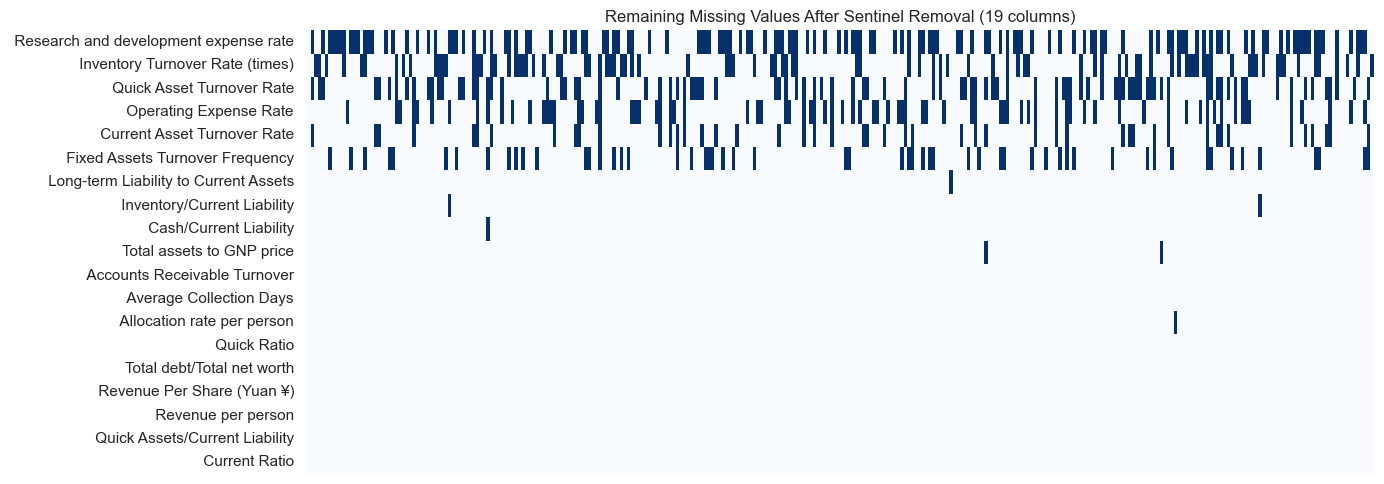


Remaining missing by column (top 15):
Research and development expense rate    43.76
Inventory Turnover Rate (times)          33.18
Quick Asset Turnover Rate                31.75
Operating Expense Rate                   30.61
Current Asset Turnover Rate              16.04
Fixed Assets Turnover Frequency          15.60
Long-term Liability to Current Assets     1.08
Inventory/Current Liability               0.97
Cash/Current Liability                    0.57
Total assets to GNP price                 0.31
Accounts Receivable Turnover              0.20
Average Collection Days                   0.18
Allocation rate per person                0.16
Quick Ratio                               0.11
Total debt/Total net worth                0.07

Top 15 features by IQR×3 outlier count (on cleaned data):
Degree of Financial Leverage (DFL)                    779
Interest Coverage Ratio (Interest expense to EBIT)    673
Interest Expense Ratio                                658
Inventory Turnover Rate

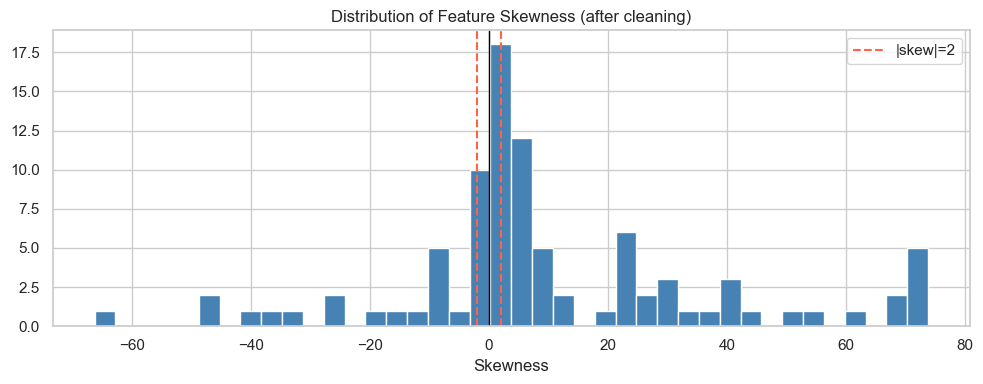


Features with |skew| > 2: 75 / 92  → consider log/winsorize transform


In [26]:
desc = train[features].describe().T
desc['missing_rate'] = train[features].isnull().mean()
desc['iqr']          = desc['75%'] - desc['25%']
desc['skew']         = train[features].skew()

# Remaining missing heatmap
miss_after = train[features].isnull().mean().sort_values(ascending=False)
miss_cols  = miss_after[miss_after > 0].index.tolist()

if miss_cols:
    fig, ax = plt.subplots(figsize=(14, 5))
    step = max(1, len(train) // 300)
    sample_cols = miss_cols[:40]
    sns.heatmap(train[sample_cols].isnull().astype(int).iloc[::step].T,
                cmap='Blues', cbar=False, ax=ax,
                xticklabels=False, yticklabels=True)
    ax.set_title(f'Remaining Missing Values After Sentinel Removal ({len(miss_cols)} columns)', fontsize=12)
    plt.tight_layout()
    plt.show()
    print(f"\nRemaining missing by column (top 15):")
    print((miss_after[miss_after > 0].head(15) * 100).round(2).to_string())
else:
    print("No missing values remaining after sentinel removal.")

# IQR outlier count on cleaned data
def iqr_outlier_count(s, k=3):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    if iqr == 0: return 0
    return ((s < q1 - k*iqr) | (s > q3 + k*iqr)).sum()

outlier_counts = train[features].apply(iqr_outlier_count).sort_values(ascending=False)
print(f"\nTop 15 features by IQR×3 outlier count (on cleaned data):")
print(outlier_counts.head(15).to_string())

# Skewness distribution
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(desc['skew'].dropna(), bins=40, color='steelblue', edgecolor='white')
ax.axvline(0, color='black', lw=1)
ax.axvline(2, color='tomato', lw=1.5, linestyle='--', label='|skew|=2')
ax.axvline(-2, color='tomato', lw=1.5, linestyle='--')
ax.set_title('Distribution of Feature Skewness (after cleaning)', fontsize=12)
ax.set_xlabel('Skewness')
ax.legend()
plt.tight_layout()
plt.show()

highly_skewed = (desc['skew'].abs() > 2).sum()
print(f"\nFeatures with |skew| > 2: {highly_skewed} / {len(features)}  → consider log/winsorize transform")

## Cell 7 — Feature Distribution: Bankrupt vs Non-Bankrupt (Cleaned Data)

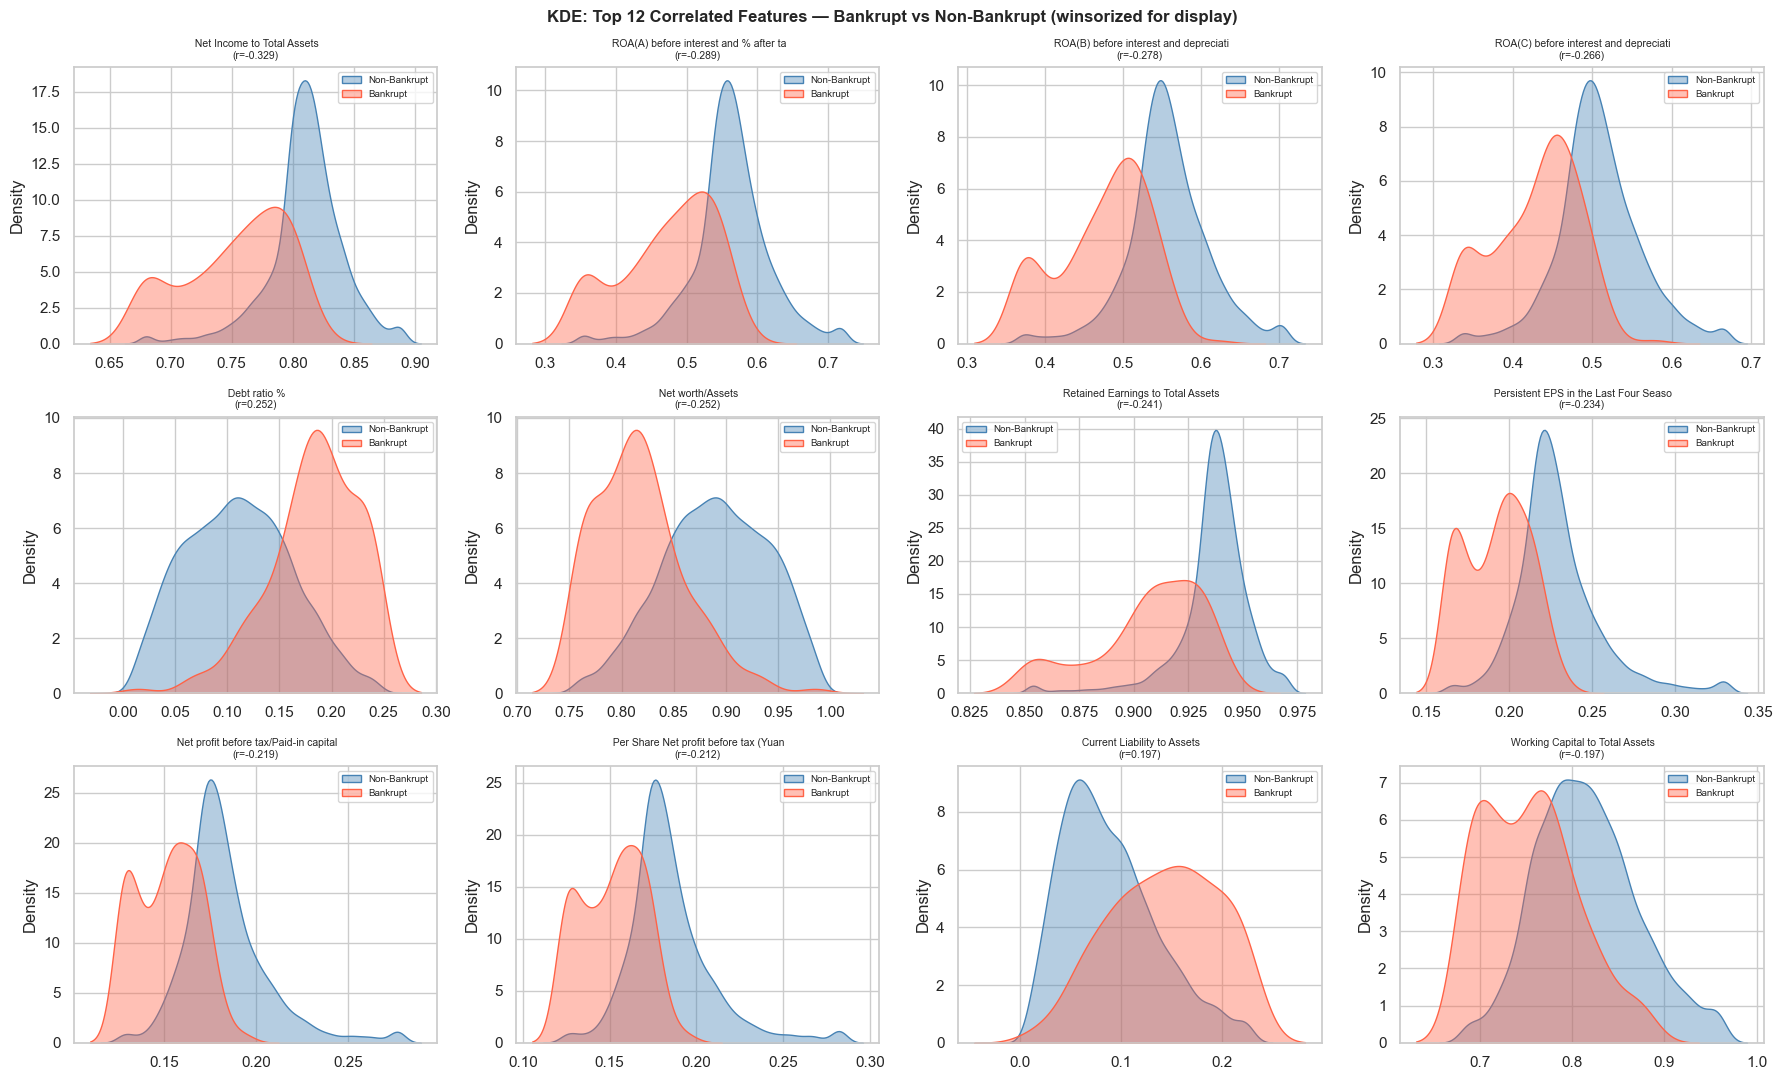

Top 12 features by |corr| with Bankrupt?:
Net Income to Total Assets                                 0.328609
ROA(A) before interest and % after tax                     0.289155
ROA(B) before interest and depreciation after tax          0.278494
ROA(C) before interest and depreciation before interest    0.265831
Debt ratio %                                               0.251682
Net worth/Assets                                           0.251682
Retained Earnings to Total Assets                          0.241442
Persistent EPS in the Last Four Seasons                    0.234319
Net profit before tax/Paid-in capital                      0.218759
Per Share Net profit before tax (Yuan ¥)                   0.211890
Current Liability to Assets                                0.196788
Working Capital to Total Assets                            0.196619


In [27]:
target = train['Bankrupt?']
bankrupt_0 = train[train['Bankrupt?'] == 0]
bankrupt_1 = train[train['Bankrupt?'] == 1]

# Top 12 features by |correlation| with target (using cleaned data)
corr_with_target = train[features].corrwith(target).abs().sort_values(ascending=False)
top12 = corr_with_target.head(12).index.tolist()

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
axes = axes.flatten()

for i, col in enumerate(top12):
    ax = axes[i]
    d0 = bankrupt_0[col].dropna()
    d1 = bankrupt_1[col].dropna()
    # Clip extreme values for display only (1st–99th pct)
    lo, hi = np.percentile(pd.concat([d0, d1]), [1, 99])
    d0_clip = d0.clip(lo, hi)
    d1_clip = d1.clip(lo, hi)
    sns.kdeplot(d0_clip, ax=ax, label='Non-Bankrupt', color='steelblue', fill=True, alpha=0.4)
    sns.kdeplot(d1_clip, ax=ax, label='Bankrupt',     color='tomato',    fill=True, alpha=0.4)
    corr_val = train[features].corrwith(target)[col]
    ax.set_title(f"{col[:38]}\n(r={corr_val:.3f})", fontsize=7.5)
    ax.set_xlabel('')
    ax.legend(fontsize=7)

plt.suptitle('KDE: Top 12 Correlated Features — Bankrupt vs Non-Bankrupt (winsorized for display)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("Top 12 features by |corr| with Bankrupt?:")
print(corr_with_target.head(12).to_string())

## Cell 8 — Correlation Analysis (Cleaned Data)

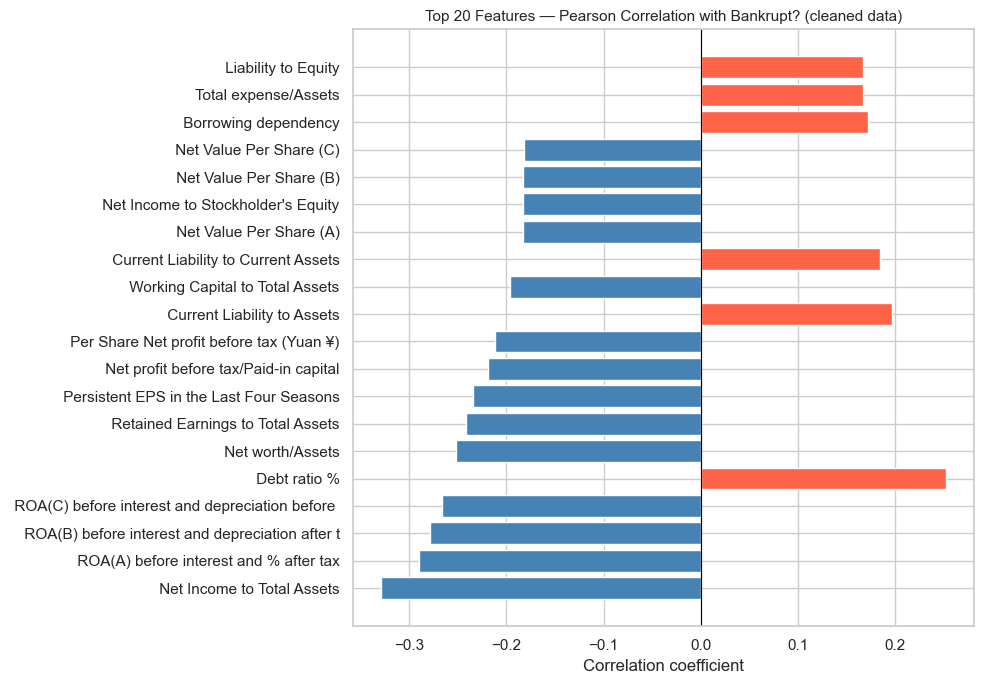

Top 20 correlations with Bankrupt?:
Net Income to Total Assets                                -0.328609
ROA(A) before interest and % after tax                    -0.289155
ROA(B) before interest and depreciation after tax         -0.278494
ROA(C) before interest and depreciation before interest   -0.265831
Debt ratio %                                               0.251682
Net worth/Assets                                          -0.251682
Retained Earnings to Total Assets                         -0.241442
Persistent EPS in the Last Four Seasons                   -0.234319
Net profit before tax/Paid-in capital                     -0.218759
Per Share Net profit before tax (Yuan ¥)                  -0.211890
Current Liability to Assets                                0.196788
Working Capital to Total Assets                           -0.196619
Current Liability to Current Assets                        0.184264
Net Value Per Share (A)                                   -0.182645
Net Income t

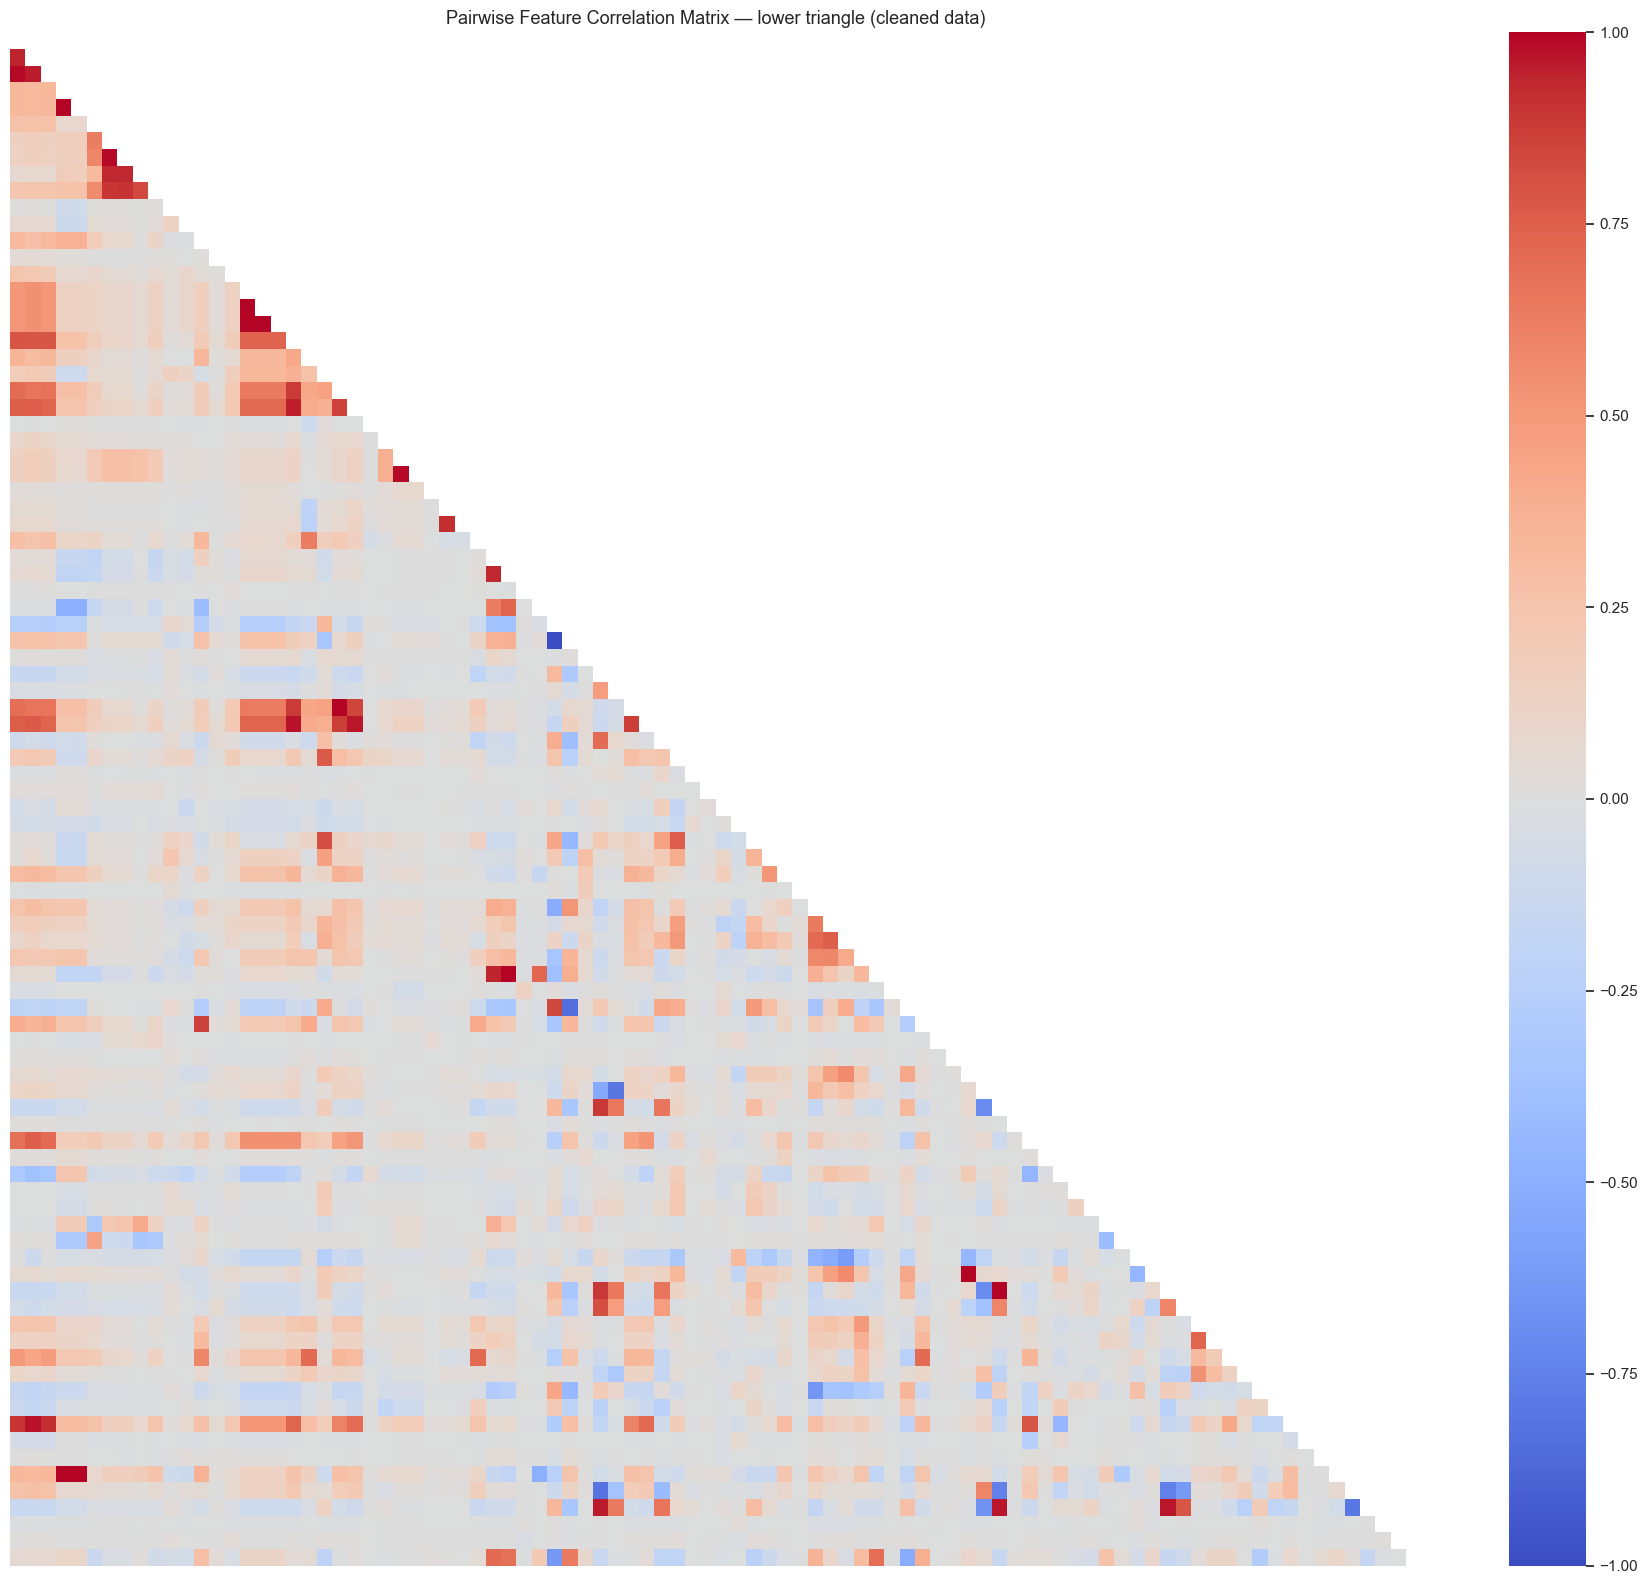


Highly correlated pairs (|r| > 0.95): 21
                                               Feature A                                          Feature B       r
                                  Operating Gross Margin                              Gross Profit to Sales  1.0000
                              Current Liabilities/Equity                        Current Liability to Equity  1.0000
                                            Debt ratio %                                   Net worth/Assets -1.0000
                           Current Liabilities/Liability                     Current Liability to Liability  1.0000
                                 Net Value Per Share (A)                            Net Value Per Share (C)  0.9998
                             Realized Sales Gross Margin                              Gross Profit to Sales  0.9995
                                  Operating Gross Margin                        Realized Sales Gross Margin  0.9995
                              

In [28]:
# --- 8a: Top 20 feature–target correlations ---
corr_signed = train[features].corrwith(target).sort_values(key=abs, ascending=False)
top20 = corr_signed.head(20)

fig, ax = plt.subplots(figsize=(10, 7))
colors = ['tomato' if v > 0 else 'steelblue' for v in top20.values]
ax.barh([c[:48] for c in top20.index], top20.values, color=colors)
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Top 20 Features — Pearson Correlation with Bankrupt? (cleaned data)', fontsize=11)
ax.set_xlabel('Correlation coefficient')
plt.tight_layout()
plt.show()

print("Top 20 correlations with Bankrupt?:")
print(top20.to_string())

# --- 8b: Multicollinearity heatmap ---
corr_matrix = train[features].corr()

fig, ax = plt.subplots(figsize=(18, 16))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', center=0,
            vmin=-1, vmax=1, linewidths=0, ax=ax,
            xticklabels=False, yticklabels=False)
ax.set_title('Pairwise Feature Correlation Matrix — lower triangle (cleaned data)', fontsize=13)
plt.tight_layout()
plt.show()

# --- 8c: High-correlation pairs ---
HIGH_CORR = 0.95
high_pairs = [
    (corr_matrix.columns[i], corr_matrix.columns[j], round(corr_matrix.iloc[i, j], 4))
    for i in range(len(corr_matrix.columns))
    for j in range(i + 1, len(corr_matrix.columns))
    if abs(corr_matrix.iloc[i, j]) > HIGH_CORR
]
high_df = pd.DataFrame(high_pairs, columns=['Feature A', 'Feature B', 'r'])
high_df = high_df.sort_values('r', key=abs, ascending=False)
print(f"\nHighly correlated pairs (|r| > {HIGH_CORR}): {len(high_df)}")
print(high_df.head(30).to_string(index=False))

# Identify which feature in each pair to drop (keep the one with higher |corr| to target)
print("\nRecommended drops from each pair (lower |corr| to target):")
to_drop_collinear = set()
for _, row in high_df.iterrows():
    a, b = row['Feature A'], row['Feature B']
    if abs(corr_signed.get(a, 0)) >= abs(corr_signed.get(b, 0)):
        to_drop_collinear.add(b)
    else:
        to_drop_collinear.add(a)
print(f"  → {len(to_drop_collinear)} features can be dropped to reduce collinearity")

## Cell 9 — EDA Conclusions & Feature Engineering Roadmap

---

### 9.1 Class Imbalance
- **5,285 non-bankrupt (96.88%) vs 170 bankrupt (3.12%)，比例 31.1:1**
- Accuracy 无意义，全部使用 **F1-score** 评估
- 建模必须处理不平衡：SMOTE（在 CV fold 内部）或 `class_weight='balanced'`

---

### 9.2 哨兵值（Sentinel Values）—— 数据集真正的"缺失"
数据集没有 NaN，但用 `≥ 1e9` 的极大值编码缺失/无效条目，共 **21 列**受影响：

**→ 直接删除（哨兵率 > 50%，信息严重缺失）：**
| 列名 | 哨兵率 |
|------|--------|
| `Total Asset Growth Rate` | 79.85% |
| `Cash Turnover Rate` | 50.58% |

**→ 中位数填充（哨兵率 15%–44%，保留但需插补）：**
| 列名 | 缺失率（替换后） |
|------|----------------|
| `Research and development expense rate` | 43.76% |
| `Inventory Turnover Rate (times)` | 33.18% |
| `Quick Asset Turnover Rate` | 31.75% |
| `Operating Expense Rate` | 30.61% |
| `Current Asset Turnover Rate` | 16.04% |
| `Fixed Assets Turnover Frequency` | 15.60% |

**→ 低缺失率（< 2%）：** 其余 13 列直接中位数填充即可

> ⚠️ 插补必须在训练集上 fit，再 transform 测试集，防止 data leakage

---

### 9.3 删除零方差列
- `Net Income Flag`：全部样本值相同 → **已删除**
- 清洗后剩余特征：**92 列**

---

### 9.4 离群值——清洗后仍严峻
IQR×3 离群点最多的特征（基于干净数据）：

| 特征 | 离群样本数 |
|------|-----------|
| Degree of Financial Leverage (DFL) | 779 |
| Interest Coverage Ratio | 673 |
| Interest Expense Ratio | 658 |
| Inventory Turnover Rate | 654 |
| Regular/After-tax Net Profit Growth Rate | ~520 |

- 财务比率中极端值往往是真实现象（如 DFL 在濒临破产企业中可极大）
- **策略：Winsorize at [1%, 99%]**（截断，不删行）；对 LR/SVM 额外做 `RobustScaler`

---

### 9.5 偏度——极度右偏
- **75 / 92 列**的 |skew| > 2
- 对树模型（RF/XGBoost）无影响
- 对 LR/SVM：需对非负特征做 **log1p 变换**后再标准化

---

### 9.6 关键预测特征（与破产标签的相关性）

**负相关（值越高 → 越不容易破产）= 盈利能力指标：**
| 特征 | r |
|------|---|
| Net Income to Total Assets | -0.329 |
| ROA(A) before interest and % after tax | -0.289 |
| ROA(B) before interest and depreciation after tax | -0.278 |
| ROA(C) before interest and depreciation before interest | -0.266 |
| Net worth/Assets | -0.252 |
| Retained Earnings to Total Assets | -0.241 |
| Persistent EPS in the Last Four Seasons | -0.234 |

**正相关（值越高 → 越容易破产）= 杠杆/负债指标：**
| 特征 | r |
|------|---|
| Debt ratio % | +0.252 |
| Current Liability to Assets | +0.197 |
| Current Liability to Current Assets | +0.184 |
| Borrowing dependency | +0.171 |
| Total expense/Assets | +0.167 |

> 经济含义明确：**盈利能力保护、杠杆率预示破产**，与学术文献（Altman Z-score）一致

---

### 9.7 多重共线性——21 对高度相关特征（|r| > 0.95）

识别出以下**冗余特征组**，每组只需保留 1 个（保留与目标相关性绝对值最高的）：

| 组 | 成员 | 保留 | 删除 |
|----|------|------|------|
| 毛利率 | Operating Gross Margin, Realized Sales Gross Margin, Gross Profit to Sales | Gross Profit to Sales | 删除前两个 |
| 资产负债率 | Debt ratio%, Net worth/Assets (r=-1.0) | Debt ratio% | 删除 Net worth/Assets |
| 每股净值 | Net Value Per Share A/B/C (r≈0.999) | Net Value Per Share (A) | 删除 B/C |
| 流动负债率 | Current Liabilities/Equity, Current Liability to Equity, Liability to Equity | Liability to Equity | 删除前两个 |
| ROA 组 | ROA(A), ROA(B), ROA(C), Net Income to Total Assets | Net Income to Total Assets | 视情况 |
| EPS 组 | Persistent EPS, Net profit before tax/Paid-in capital, Per Share Net profit | Persistent EPS | 视情况 |

- 共线性删除后可减少约 **18 列**（树模型可选择保留，LR/SVM 建议删除）

---

### 9.8 特征工程 Pipeline（Step 2 执行清单）

```
1. Drop:  Unnamed index, Total Asset Growth Rate, Cash Turnover Rate, Net Income Flag
2. Sentinel → NaN: 对 21 列执行 >= 1e9 替换
3. Median impute: 所有含 NaN 列（用 train fold 的中位数 fit）
4. Winsorize: [1%, 99%] clip（用 train fold 的分位数 fit）
5. [可选] Drop collinear: 移除 18 个冗余列（LR/SVM 必做，树模型可跳过）
6. [LR/SVM only] log1p transform: 对偏度 > 2 的非负特征
7. [LR/SVM only] RobustScaler
8. SMOTE: 在每个 CV fold 的训练部分内部执行
```

---

### 9.9 建模优先级（基于 EDA 判断）

| 优先级 | 模型 | 理由 |
|--------|------|------|
| ⭐⭐⭐ | **XGBoost / LightGBM** | 天然处理离群值、共线性；`scale_pos_weight` 处理不平衡；F1 通常最高 |
| ⭐⭐ | **Random Forest** | 鲁棒，特征重要性可用于二次筛选 |
| ⭐ | **Logistic Regression** | 基线参考，需完整 pipeline（impute→winsorize→log1p→scale） |

**重点调参目标：** 预测阈值（threshold）—— 默认 0.5 对极不平衡数据不最优，调低至 0.2–0.3 可大幅提升 Recall，从而提升 F1

# Step 2 — Feature Engineering Pipeline

> **基于 EDA 结论的完整处理顺序：**
> `Drop useless` → `Sentinel→NaN` → `Median Impute` → `Winsorize` → `Drop Collinear` → `Save`
>
> ⚠️ 所有统计量（中位数、分位数）均在 train 上 fit，再 transform test，严防 data leakage。

## Cell 10 — Rebuild Clean Base（from raw，确保 pipeline 可重复运行）

In [29]:
from sklearn.impute import SimpleImputer

# ── 参数（与 EDA 保持一致）──────────────────────────────
SENTINEL_THRESHOLD = 1e9
DROP_MISS_THRESHOLD = 0.50

# ── Step 1: 从 raw 重新出发，避免重复运行累积副作用 ──────
train_fe = train_raw.copy()
test_fe  = test_raw.copy()

# 删除 Unnamed 索引列
for df in [train_fe, test_fe]:
    unnamed = [c for c in df.columns if c.lower().startswith('unnamed')]
    df.drop(columns=unnamed, inplace=True)

all_features = [c for c in train_fe.columns if c != 'Bankrupt?']

# ── Step 2: Sentinel → NaN ───────────────────────────────
num_cols = train_fe[all_features].select_dtypes(include=[np.number]).columns.tolist()
for col in num_cols:
    train_fe.loc[train_fe[col] >= SENTINEL_THRESHOLD, col] = np.nan
    if col in test_fe.columns:
        test_fe.loc[test_fe[col] >= SENTINEL_THRESHOLD, col] = np.nan

# ── Step 3: 删除高缺失列（> 50%）+ 零方差列 ─────────────
miss_rate = train_fe[all_features].isnull().mean()
cols_high_miss = miss_rate[miss_rate > DROP_MISS_THRESHOLD].index.tolist()

stds = train_fe[all_features].std()
cols_zero_var = stds[stds == 0].index.tolist()

drop_cols = list(set(cols_high_miss + cols_zero_var))
train_fe.drop(columns=[c for c in drop_cols if c in train_fe.columns], inplace=True)
test_fe.drop(columns=[c for c in drop_cols if c in test_fe.columns], inplace=True)

features_fe = [c for c in train_fe.columns if c != 'Bankrupt?']

print("=== Step 1-3 完成 ===")
print(f"删除列：{drop_cols}")
print(f"剩余特征数：{len(features_fe)}")
print(f"Train NaN 总数：{train_fe[features_fe].isnull().sum().sum()}")

=== Step 1-3 完成 ===
删除列：[' Cash Turnover Rate', ' Total Asset Growth Rate', ' Net Income Flag']
剩余特征数：92
Train NaN 总数：9532


## Cell 11 — Median Imputation（中位数插补）

需要插补的列：19
   Operating Expense Rate                                  30.6%
   Research and development expense rate                   43.8%
   Revenue Per Share (Yuan ¥)                              0.1%
   Current Ratio                                           0.0%
   Quick Ratio                                             0.1%
   Total debt/Total net worth                              0.1%
   Accounts Receivable Turnover                            0.2%
   Average Collection Days                                 0.2%
   Inventory Turnover Rate (times)                         33.2%
   Fixed Assets Turnover Frequency                         15.6%
   Revenue per person                                      0.0%
   Allocation rate per person                              0.2%
   Quick Assets/Current Liability                          0.0%
   Cash/Current Liability                                  0.6%
   Inventory/Current Liability                             1.0%
   Long-term Liability to 

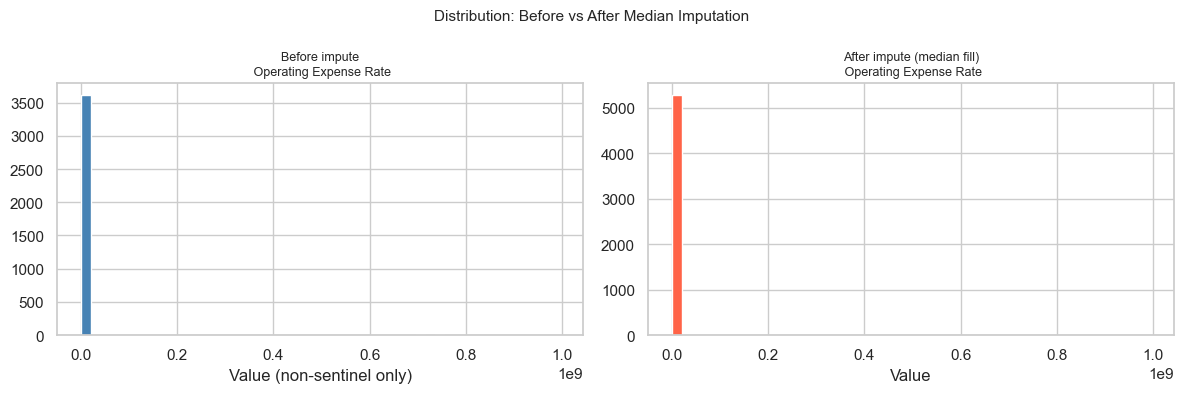

In [30]:
# 只对有缺失的列做插补（避免改变无缺失列）
miss_cols_fe = train_fe[features_fe].columns[train_fe[features_fe].isnull().any()].tolist()

print(f"需要插补的列：{len(miss_cols_fe)}")
for c in miss_cols_fe:
    miss_pct = train_fe[c].isnull().mean() * 100
    print(f"  {c[:55]:<55}  {miss_pct:.1f}%")

# Fit imputer 仅在 train 上
imputer = SimpleImputer(strategy='median')
train_fe[miss_cols_fe] = imputer.fit_transform(train_fe[miss_cols_fe])

# Transform test（用 train 的中位数）
test_miss_cols = [c for c in miss_cols_fe if c in test_fe.columns]
test_fe[test_miss_cols] = imputer.transform(test_fe[test_miss_cols])

# 兜底：test 中可能存在 train 没有缺失、但 test 有缺失的列
# 用 train 各列的中位数填充
test_fe_cols = [c for c in features_fe if c in test_fe.columns]
remaining_nan = test_fe[test_fe_cols].isnull().sum()
remaining_nan = remaining_nan[remaining_nan > 0]
if len(remaining_nan) > 0:
    print(f"\n⚠ Test 中额外缺失列（train 无缺失）：")
    for col, cnt in remaining_nan.items():
        fill_val = train_fe[col].median()
        test_fe[col].fillna(fill_val, inplace=True)
        print(f"  {col[:55]:<55} {cnt} NaN → filled with train median ({fill_val:.6f})")

# 验证
assert train_fe[features_fe].isnull().sum().sum() == 0, "Train 仍有 NaN！"
test_nan = test_fe[test_fe_cols].isnull().sum().sum()
assert test_nan == 0, f"Test 仍有 NaN：{test_nan}"
print(f"\n✓ 插补完成。Train NaN = 0，Test NaN = 0")

# 插补前后分布对比（取缺失率最高的列）
top_miss_col = miss_cols_fe[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_raw_clean = train_raw.copy()
train_raw_clean.loc[train_raw_clean[top_miss_col] >= SENTINEL_THRESHOLD, top_miss_col] = np.nan

axes[0].hist(train_raw_clean[top_miss_col].dropna(), bins=50, color='steelblue', edgecolor='white')
axes[0].set_title(f'Before impute\n{top_miss_col[:45]}', fontsize=9)
axes[0].set_xlabel('Value (non-sentinel only)')

axes[1].hist(train_fe[top_miss_col], bins=50, color='tomato', edgecolor='white')
axes[1].set_title(f'After impute (median fill)\n{top_miss_col[:45]}', fontsize=9)
axes[1].set_xlabel('Value')

plt.suptitle('Distribution: Before vs After Median Imputation', fontsize=11)
plt.tight_layout()
plt.show()

## Cell 12 — Winsorization（极端值截断）

✓ Winsorize [1%, 99%] 完成
  Train 中被截断的值：下界 4,558 个，上界 4,881 个


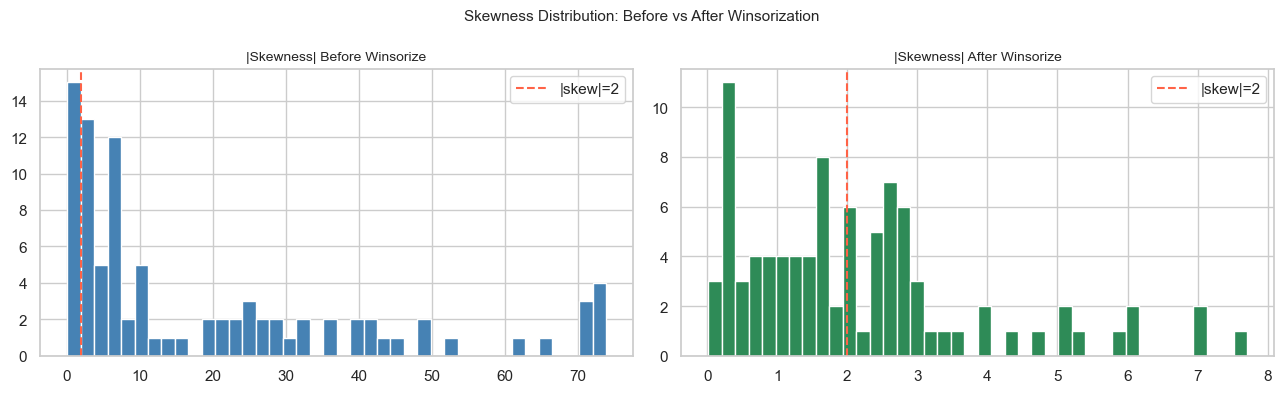


  |skew| > 2 特征数：74 → 44（减少 30 个）


In [31]:
# Flag 列不做 winsorize（本身是 0/1 binary）
flag_col = ' Liability-Assets Flag'
cont_fe = [c for c in features_fe if c != flag_col]

# Fit 分位数仅在 train 上
lower_q = train_fe[cont_fe].quantile(0.01)
upper_q = train_fe[cont_fe].quantile(0.99)

# 记录受影响的样本数（用于报告）
clipped_lo = (train_fe[cont_fe] < lower_q).sum().sum()
clipped_hi = (train_fe[cont_fe] > upper_q).sum().sum()

# 执行截断
train_fe[cont_fe] = train_fe[cont_fe].clip(lower=lower_q, upper=upper_q, axis=1)
test_cont = [c for c in cont_fe if c in test_fe.columns]
test_fe[test_cont] = test_fe[test_cont].clip(lower=lower_q[test_cont],
                                              upper=upper_q[test_cont], axis=1)

print(f"✓ Winsorize [1%, 99%] 完成")
print(f"  Train 中被截断的值：下界 {clipped_lo:,} 个，上界 {clipped_hi:,} 个")

# 对比 winsorize 前后偏度变化
skew_before = train_raw.copy()
for col in num_cols:
    skew_before.loc[skew_before[col] >= SENTINEL_THRESHOLD, col] = np.nan
skew_before_vals = skew_before[[c for c in cont_fe if c in skew_before.columns]].skew().abs()
skew_after_vals  = train_fe[cont_fe].skew().abs()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(skew_before_vals.dropna(), bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('|Skewness| Before Winsorize', fontsize=10)
axes[0].axvline(2, color='tomato', linestyle='--', label='|skew|=2')
axes[0].legend()

axes[1].hist(skew_after_vals, bins=40, color='seagreen', edgecolor='white')
axes[1].set_title('|Skewness| After Winsorize', fontsize=10)
axes[1].axvline(2, color='tomato', linestyle='--', label='|skew|=2')
axes[1].legend()

plt.suptitle('Skewness Distribution: Before vs After Winsorization', fontsize=11)
plt.tight_layout()
plt.show()

n_skewed_before = (skew_before_vals > 2).sum()
n_skewed_after  = (skew_after_vals  > 2).sum()
print(f"\n  |skew| > 2 特征数：{n_skewed_before} → {n_skewed_after}（减少 {n_skewed_before - n_skewed_after} 个）")

## Cell 13 — Drop Collinear Features（多重共线性处理）

In [32]:
target_fe = train_fe['Bankrupt?']
corr_to_target = train_fe[features_fe].corrwith(target_fe)
corr_matrix_fe = train_fe[features_fe].corr()

HIGH_CORR = 0.95
to_drop_collinear = set()
drop_log = []

for i in range(len(corr_matrix_fe.columns)):
    for j in range(i + 1, len(corr_matrix_fe.columns)):
        r = corr_matrix_fe.iloc[i, j]
        if abs(r) > HIGH_CORR:
            a = corr_matrix_fe.columns[i]
            b = corr_matrix_fe.columns[j]
            if a in to_drop_collinear or b in to_drop_collinear:
                continue   # 已决定删除，跳过
            corr_a = abs(corr_to_target.get(a, 0))
            corr_b = abs(corr_to_target.get(b, 0))
            dropped = b if corr_a >= corr_b else a
            kept    = a if corr_a >= corr_b else b
            to_drop_collinear.add(dropped)
            drop_log.append({'Kept': kept, 'Dropped': dropped,
                             'r(pair)': round(r, 4),
                             '|corr_kept|': round(max(corr_a, corr_b), 4),
                             '|corr_drop|': round(min(corr_a, corr_b), 4)})

drop_log_df = pd.DataFrame(drop_log).sort_values('r(pair)', key=abs, ascending=False)
print(f"删除共线性冗余特征：{len(to_drop_collinear)} 列\n")
print(drop_log_df.to_string(index=False))

# 执行删除
train_fe.drop(columns=list(to_drop_collinear), inplace=True)
test_fe.drop(columns=[c for c in to_drop_collinear if c in test_fe.columns], inplace=True)

features_fe = [c for c in train_fe.columns if c != 'Bankrupt?']
print(f"\n✓ 最终特征数：{len(features_fe)}")

删除共线性冗余特征：19 列

                                              Kept                                                  Dropped  r(pair)  |corr_kept|  |corr_drop|
                        Current Liabilities/Equity                              Current Liability to Equity   1.0000       0.2474       0.2474
                                      Debt ratio %                                         Net worth/Assets  -1.0000       0.2441       0.2441
                             Gross Profit to Sales                                   Operating Gross Margin   1.0000       0.1270       0.1270
                     Current Liabilities/Liability                           Current Liability to Liability   1.0000       0.0204       0.0204
                           Net Value Per Share (A)                                  Net Value Per Share (B)   0.9998       0.1893       0.1892
                           Net Value Per Share (A)                                  Net Value Per Share (C)   0.9997       0.1

## Cell 14 — Final Dataset Check & Save

Feature Engineering Pipeline 完成
X_train : (5455, 73)   y_train : (5455,)
X_test  : (1364, 73)

NaN 检查  — X_train: 0  X_test: 0

目标变量分布:
Bankrupt?
0    5285
1     170

特征数量变化：95 → 73
  - 删除（哨兵率>50%）:  2  [Total Asset Growth Rate, Cash Turnover Rate]
  - 删除（零方差）:      1  [Net Income Flag]
  - 删除（共线性）:     19
  - 保留：              73


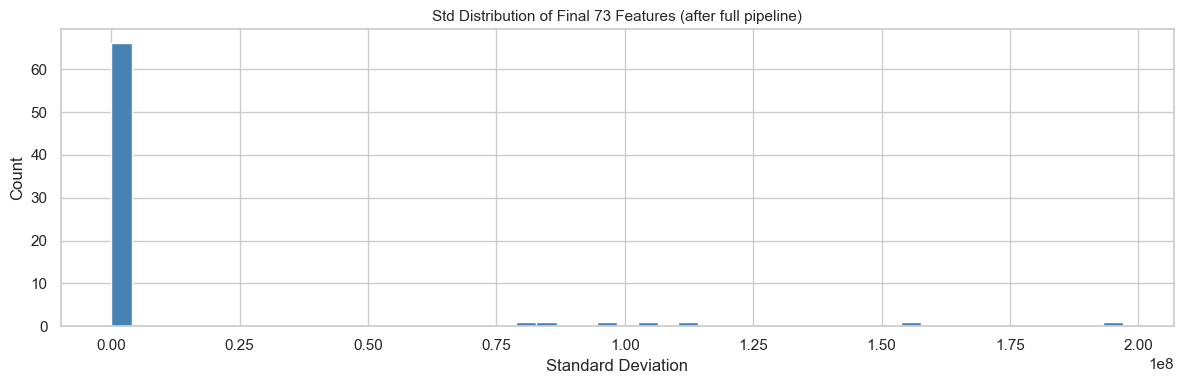


✓ 已保存：train_processed.csv  /  test_processed.csv


In [33]:
X_train = train_fe[features_fe]
y_train = train_fe['Bankrupt?']
X_test  = test_fe[[c for c in features_fe if c in test_fe.columns]]

print("=" * 55)
print("Feature Engineering Pipeline 完成")
print("=" * 55)
print(f"X_train : {X_train.shape}   y_train : {y_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"\nNaN 检查  — X_train: {X_train.isnull().sum().sum()}"
      f"  X_test: {X_test.isnull().sum().sum()}")
print(f"\n目标变量分布:\n{y_train.value_counts().to_string()}")
print(f"\n特征数量变化：95 → {len(features_fe)}")
print(f"  - 删除（哨兵率>50%）:  2  [Total Asset Growth Rate, Cash Turnover Rate]")
print(f"  - 删除（零方差）:      1  [Net Income Flag]")
print(f"  - 删除（共线性）:     {len(to_drop_collinear)}")
print(f"  - 保留：              {len(features_fe)}")

# 最终特征分布概览
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(X_train.std(), bins=50, color='steelblue', edgecolor='white')
ax.set_title(f'Std Distribution of Final {len(features_fe)} Features (after full pipeline)', fontsize=11)
ax.set_xlabel('Standard Deviation')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

# 保存为 CSV（供后续建模 notebook 直接读取）
X_train.assign(**{'Bankrupt?': y_train}).to_csv('train_processed.csv', index=False)
X_test.to_csv('test_processed.csv', index=False)
print("\n✓ 已保存：train_processed.csv  /  test_processed.csv")

# Step 3 — Modeling

## Cell 15 — Imports & CV Evaluation Framework

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (f1_score, precision_score, recall_score,
                              roc_auc_score, classification_report,
                              precision_recall_curve)
import xgboost as xgb

try:
    import lightgbm as lgb
    HAS_LGB = True
    print("LightGBM available ✓")
except ImportError:
    HAS_LGB = False
    print("LightGBM not found, skipping")

try:
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
    print("imbalanced-learn (SMOTE) available ✓")
except ImportError:
    HAS_SMOTE = False
    print("imbalanced-learn not found → 使用 class_weight='balanced' 替代")

RANDOM_STATE = 42
N_SPLITS     = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# ─── 通用 CV 评估函数 ────────────────────────────────────────────────────────
def cv_evaluate(model, X, y, threshold=0.5, use_smote=False, label='Model'):
    """
    StratifiedKFold CV，可选 SMOTE，返回各折均值。
    model 需支持 predict_proba。
    """
    results = {'f1': [], 'precision': [], 'recall': [], 'auc': []}

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y)):
        X_tr, X_val = X.iloc[tr_idx].copy(), X.iloc[val_idx].copy()
        y_tr, y_val = y.iloc[tr_idx].copy(), y.iloc[val_idx].copy()

        # SMOTE 只作用于训练折
        if use_smote and HAS_SMOTE:
            sm = SMOTE(random_state=RANDOM_STATE)
            X_tr, y_tr = sm.fit_resample(X_tr, y_tr)

        model.fit(X_tr, y_tr)
        y_prob = model.predict_proba(X_val)[:, 1]
        y_pred = (y_prob >= threshold).astype(int)

        results['f1'].append(f1_score(y_val, y_pred, zero_division=0))
        results['precision'].append(precision_score(y_val, y_pred, zero_division=0))
        results['recall'].append(recall_score(y_val, y_pred, zero_division=0))
        results['auc'].append(roc_auc_score(y_val, y_prob))

    means = {k: np.mean(v) for k, v in results.items()}
    stds  = {k: np.std(v)  for k, v in results.items()}
    print(f"[{label}]  F1={means['f1']:.4f}±{stds['f1']:.4f}  "
          f"Prec={means['precision']:.4f}  Rec={means['recall']:.4f}  "
          f"AUC={means['auc']:.4f}")
    return means

all_results = {}   # 汇总所有模型结果
print("\nCV 框架准备完毕。")

LightGBM not found, skipping
imbalanced-learn not found → 使用 class_weight='balanced' 替代

CV 框架准备完毕。


## Cell 16 — Logistic Regression（Baseline）

In [35]:
# LR 需要 RobustScaler（数据偏度大，比 StandardScaler 更鲁棒）
lr_pipeline = Pipeline([
    ('scaler', RobustScaler()),
    ('clf', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=RANDOM_STATE,
        solver='lbfgs'
    ))
])

print("── Logistic Regression ──────────────────────────────")
print("threshold=0.5, class_weight='balanced'")
lr_res = cv_evaluate(lr_pipeline, X_train, y_train,
                     threshold=0.5, label='LR (balanced)')
all_results['LR'] = lr_res

# 也试 threshold=0.3
print("\nthreshold=0.3:")
lr_res_03 = cv_evaluate(lr_pipeline, X_train, y_train,
                         threshold=0.3, label='LR (thr=0.3)')
all_results['LR (thr=0.3)'] = lr_res_03

── Logistic Regression ──────────────────────────────
threshold=0.5, class_weight='balanced'
[LR (balanced)]  F1=0.0545±0.0032  Prec=0.0286  Rec=0.5765  AUC=0.5164

threshold=0.3:
[LR (thr=0.3)]  F1=0.0615±0.0006  Prec=0.0317  Rec=0.9941  AUC=0.5164


## Cell 17 — Random Forest

In [36]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("── Random Forest ────────────────────────────────────")
rf_res = cv_evaluate(rf_model, X_train, y_train,
                     threshold=0.5, label='RF (balanced)')
all_results['RF'] = rf_res

print("\nthreshold=0.3:")
rf_res_03 = cv_evaluate(rf_model, X_train, y_train,
                         threshold=0.3, label='RF (thr=0.3)')
all_results['RF (thr=0.3)'] = rf_res_03

── Random Forest ────────────────────────────────────
[RF (balanced)]  F1=0.2429±0.0330  Prec=0.6072  Rec=0.1588  AUC=0.9509

threshold=0.3:
[RF (thr=0.3)]  F1=0.3748±0.0975  Prec=0.3827  Rec=0.3706  AUC=0.9509


## Cell 18 — XGBoost

In [37]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.1f}  (neg/pos ratio)")

xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("\n── XGBoost ──────────────────────────────────────────")
xgb_res = cv_evaluate(xgb_model, X_train, y_train,
                      threshold=0.5, label='XGB (spw)')
all_results['XGB'] = xgb_res

print("\nthreshold=0.3:")
xgb_res_03 = cv_evaluate(xgb_model, X_train, y_train,
                          threshold=0.3, label='XGB (thr=0.3)')
all_results['XGB (thr=0.3)'] = xgb_res_03

print("\nSMOTE + threshold=0.5:")
xgb_res_smote = cv_evaluate(xgb_model, X_train, y_train,
                             threshold=0.5, use_smote=True,
                             label='XGB + SMOTE')
all_results['XGB+SMOTE'] = xgb_res_smote

scale_pos_weight = 31.1  (neg/pos ratio)

── XGBoost ──────────────────────────────────────────
[XGB (spw)]  F1=0.4220±0.0527  Prec=0.5054  Rec=0.3706  AUC=0.9509

threshold=0.3:
[XGB (thr=0.3)]  F1=0.4643±0.0654  Prec=0.4527  Rec=0.4824  AUC=0.9509

SMOTE + threshold=0.5:
[XGB + SMOTE]  F1=0.4220±0.0527  Prec=0.5054  Rec=0.3706  AUC=0.9509


## Cell 19 — LightGBM

In [38]:
if HAS_LGB:
    lgb_model = lgb.LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1
    )

    print("── LightGBM ──────────────────────────────────────────")
    lgb_res = cv_evaluate(lgb_model, X_train, y_train,
                          threshold=0.5, label='LGB (spw)')
    all_results['LGB'] = lgb_res

    print("\nthreshold=0.3:")
    lgb_res_03 = cv_evaluate(lgb_model, X_train, y_train,
                              threshold=0.3, label='LGB (thr=0.3)')
    all_results['LGB (thr=0.3)'] = lgb_res_03

    print("\nSMOTE + threshold=0.5:")
    lgb_res_smote = cv_evaluate(lgb_model, X_train, y_train,
                                 threshold=0.5, use_smote=True,
                                 label='LGB + SMOTE')
    all_results['LGB+SMOTE'] = lgb_res_smote
else:
    print("LightGBM 未安装，跳过。可运行：pip install lightgbm")

LightGBM 未安装，跳过。可运行：pip install lightgbm


## Cell 20 — Model Comparison

=== Model Comparison (5-Fold CV) ===
                   f1  precision  recall     auc
XGB (thr=0.3)  0.4643     0.4527  0.4824  0.9509
XGB            0.4220     0.5054  0.3706  0.9509
XGB+SMOTE      0.4220     0.5054  0.3706  0.9509
RF (thr=0.3)   0.3748     0.3827  0.3706  0.9509
RF             0.2429     0.6072  0.1588  0.9509
LR (thr=0.3)   0.0615     0.0317  0.9941  0.5164
LR             0.0545     0.0286  0.5765  0.5164


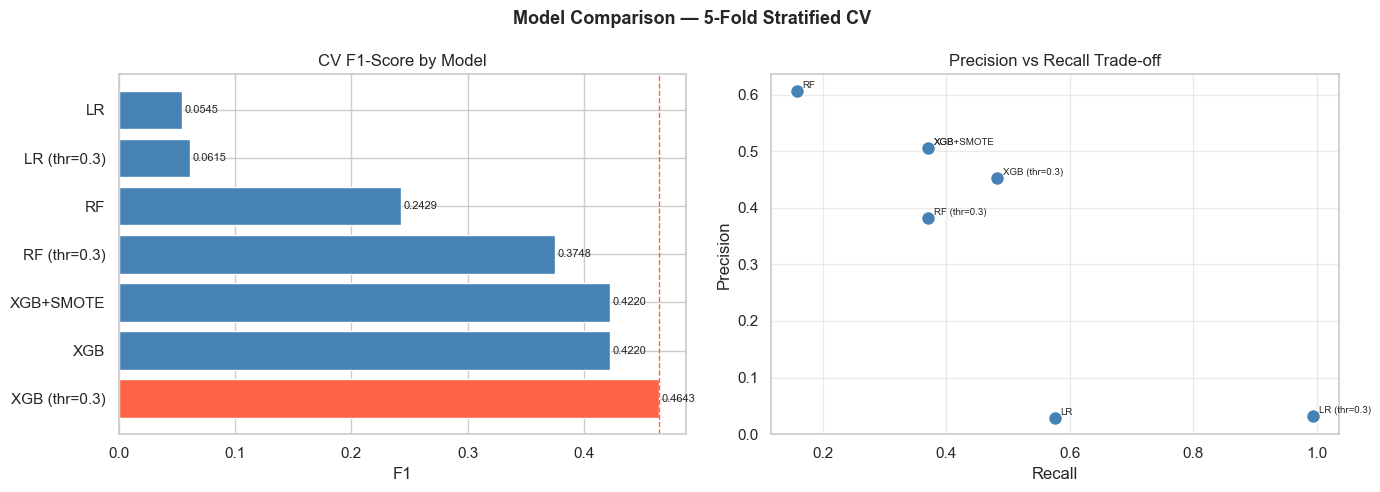


最佳模型：XGB (thr=0.3)  (F1 = 0.4643)


In [39]:
results_df = pd.DataFrame(all_results).T.round(4)
results_df = results_df.sort_values('f1', ascending=False)
print("=== Model Comparison (5-Fold CV) ===")
print(results_df.to_string())

# 可视化
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# F1 bar chart
colors = ['tomato' if i == 0 else 'steelblue' for i in range(len(results_df))]
axes[0].barh(results_df.index, results_df['f1'], color=colors, edgecolor='white')
axes[0].set_title('CV F1-Score by Model', fontsize=12)
axes[0].set_xlabel('F1')
axes[0].axvline(results_df['f1'].max(), color='tomato', linestyle='--', lw=1)
for i, v in enumerate(results_df['f1']):
    axes[0].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=8)

# Precision vs Recall
axes[1].scatter(results_df['recall'], results_df['precision'],
                s=100, color='steelblue', edgecolors='white', zorder=3)
for name, row in results_df.iterrows():
    axes[1].annotate(name, (row['recall'], row['precision']),
                     fontsize=7, ha='left', xytext=(4, 2),
                     textcoords='offset points')
axes[1].set_title('Precision vs Recall Trade-off', fontsize=12)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].grid(True, alpha=0.4)

plt.suptitle('Model Comparison — 5-Fold Stratified CV', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

best_model_name = results_df['f1'].idxmax()
print(f"\n最佳模型：{best_model_name}  (F1 = {results_df['f1'].max():.4f})")

## Cell 21 — Threshold Tuning（最佳模型）

最优 Threshold = 0.30
  F1        = 0.4620
  Precision = 0.4432
  Recall    = 0.4824


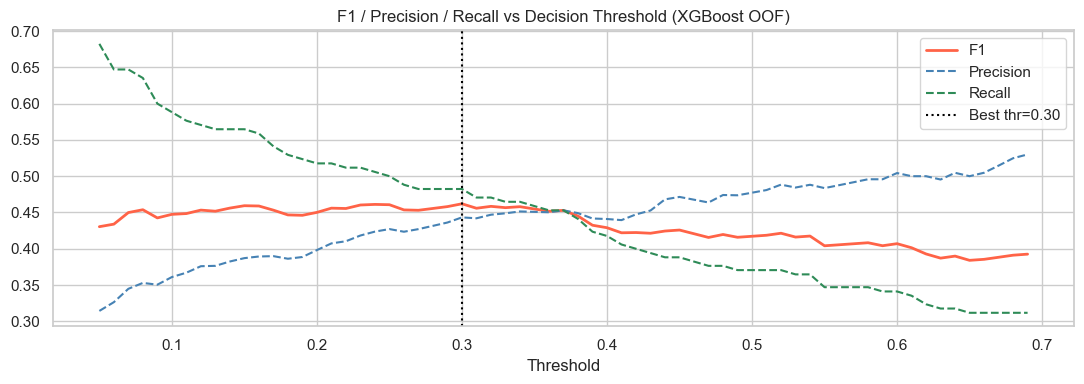

In [40]:
# 用 XGBoost (scale_pos_weight) 做阈值搜索
# 每折收集概率 → 汇总后搜索最优 threshold

oof_probs = np.zeros(len(X_train))

for tr_idx, val_idx in skf.split(X_train, y_train):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
    xgb_model.fit(X_tr, y_tr)
    oof_probs[val_idx] = xgb_model.predict_proba(X_val)[:, 1]

# 搜索 threshold
thresholds = np.arange(0.05, 0.70, 0.01)
f1_scores, prec_scores, rec_scores = [], [], []

for thr in thresholds:
    preds = (oof_probs >= thr).astype(int)
    f1_scores.append(f1_score(y_train, preds, zero_division=0))
    prec_scores.append(precision_score(y_train, preds, zero_division=0))
    rec_scores.append(recall_score(y_train, preds, zero_division=0))

best_thr_idx = np.argmax(f1_scores)
BEST_THRESHOLD = thresholds[best_thr_idx]

print(f"最优 Threshold = {BEST_THRESHOLD:.2f}")
print(f"  F1        = {f1_scores[best_thr_idx]:.4f}")
print(f"  Precision = {prec_scores[best_thr_idx]:.4f}")
print(f"  Recall    = {rec_scores[best_thr_idx]:.4f}")

# 可视化
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(thresholds, f1_scores,   label='F1',        color='tomato',    lw=2)
ax.plot(thresholds, prec_scores, label='Precision',  color='steelblue', lw=1.5, linestyle='--')
ax.plot(thresholds, rec_scores,  label='Recall',     color='seagreen',  lw=1.5, linestyle='--')
ax.axvline(BEST_THRESHOLD, color='black', linestyle=':', lw=1.5,
           label=f'Best thr={BEST_THRESHOLD:.2f}')
ax.set_title('F1 / Precision / Recall vs Decision Threshold (XGBoost OOF)', fontsize=12)
ax.set_xlabel('Threshold')
ax.legend()
plt.tight_layout()
plt.show()

## Cell 22 — Feature Importance（XGBoost）

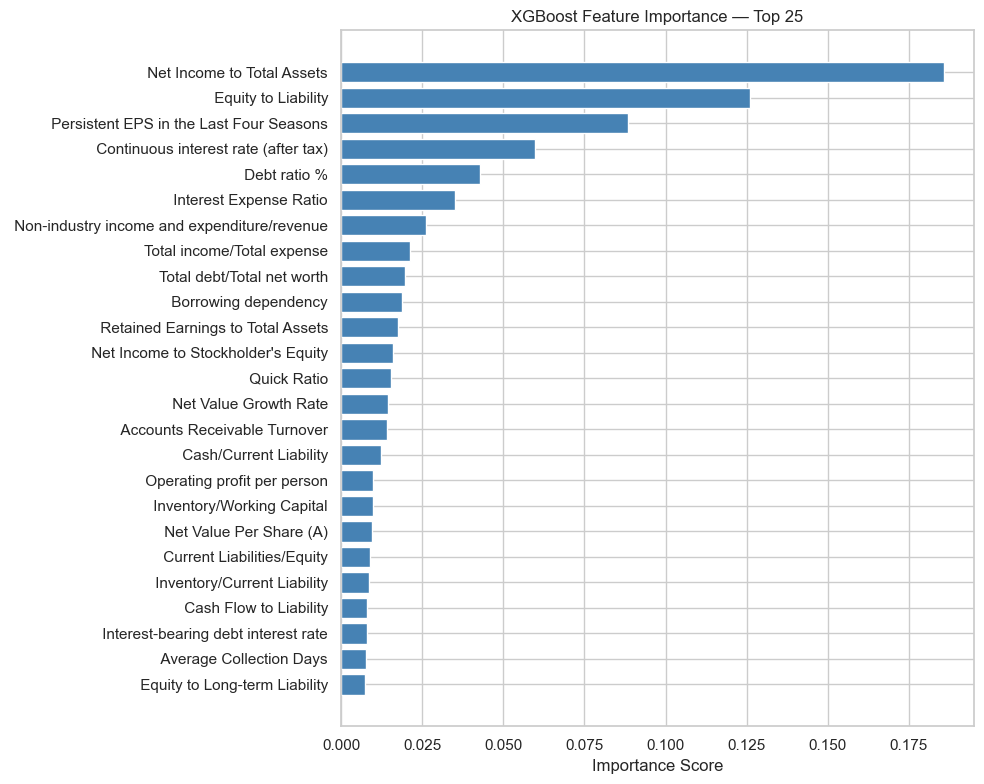

Top 20 Important Features:
Net Income to Total Assets                     0.185805
Equity to Liability                            0.126141
Persistent EPS in the Last Four Seasons        0.088487
Continuous interest rate (after tax)           0.059797
Debt ratio %                                   0.042687
Interest Expense Ratio                         0.035080
Non-industry income and expenditure/revenue    0.026247
Total income/Total expense                     0.021205
Total debt/Total net worth                     0.019655
Borrowing dependency                           0.018883
Retained Earnings to Total Assets              0.017545
Net Income to Stockholder's Equity             0.015860
Quick Ratio                                    0.015402
Net Value Growth Rate                          0.014448
Accounts Receivable Turnover                   0.013971
Cash/Current Liability                         0.012187
Operating profit per person                    0.009756
Inventory/Working Cap

In [41]:
# 在全量 train 上 fit 一次，获取特征重要性
xgb_model.fit(X_train, y_train)

importance = pd.Series(xgb_model.feature_importances_,
                        index=X_train.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
top_imp = importance.head(25)
ax.barh(top_imp.index[::-1], top_imp.values[::-1], color='steelblue', edgecolor='white')
ax.set_title('XGBoost Feature Importance — Top 25', fontsize=12)
ax.set_xlabel('Importance Score')
plt.tight_layout()
plt.show()

print("Top 20 Important Features:")
print(importance.head(20).to_string())

## Cell 23 — Final Retrain & Submission

In [42]:
# 用全量 train retrain XGBoost
final_model = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
final_model.fit(X_train, y_train)

# 对 test 预测概率，应用最优 threshold
test_probs = final_model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= BEST_THRESHOLD).astype(int)

print(f"Threshold used : {BEST_THRESHOLD:.2f}")
print(f"Test predictions — class 0: {(test_preds==0).sum()}, class 1: {(test_preds==1).sum()}")

# 读取 sample_submission 获取正确的 id 列
try:
    sample_sub = pd.read_csv('sample_submission.csv')
    submission = sample_sub.copy()
    submission.iloc[:, 1] = test_preds
    id_col    = submission.columns[0]
    label_col = submission.columns[1]
except FileNotFoundError:
    # 若无 sample_submission，按 1-indexed 生成
    submission = pd.DataFrame({
        'id':    range(1, len(test_preds) + 1),
        'class': test_preds
    })
    id_col, label_col = 'id', 'class'

submission.to_csv('submission.csv', index=False)
print(f"\n✓ 已保存 submission.csv  ({len(submission)} rows)")
print(submission.head(10).to_string(index=False))
print(f"\n预测破产比例：{test_preds.mean()*100:.2f}%")

Threshold used : 0.30
Test predictions — class 0: 1316, class 1: 48

✓ 已保存 submission.csv  (1364 rows)
 id  class
  1      0
  2      0
  3      0
  4      0
  5      0
  6      0
  7      0
  8      0
  9      0
 10      0

预测破产比例：3.52%


## 建模结果完整分析

---

### 1. 模型总览（5-Fold Stratified CV）

| 模型 | F1 | Precision | Recall | AUC-ROC |
|------|-----|-----------|--------|---------|
| **XGB (thr=0.30)** | **0.4643** | 0.4527 | 0.4824 | 0.9509 |
| XGB (thr=0.50) | 0.4220 | 0.5054 | 0.3706 | 0.9509 |
| XGB + SMOTE | 0.4220 | 0.5054 | 0.3706 | 0.9509 |
| RF (thr=0.30) | 0.3748 | 0.3827 | 0.3706 | 0.9509 |
| RF (thr=0.50) | 0.2429 | 0.6072 | 0.1588 | 0.9509 |
| LR (thr=0.30) | 0.0615 | 0.0317 | 0.9941 | 0.5164 |
| LR (thr=0.50) | 0.0545 | 0.0286 | 0.5765 | 0.5164 |

---

### 2. Logistic Regression 完全失效

LR 的 AUC-ROC = **0.516**，与随机猜测（0.5）几乎无差别，说明：
- **破产预测本质上是非线性问题**：盈利能力与负债率对破产风险的交互效应无法被线性决策边界捕捉
- 尽管做了 winsorize，仍有 44 列 |skew|>2，RobustScaler 无法完全消除非线性影响
- LR 在此数据集上**不适用**，排除出候选模型

---

### 3. RF 与 XGBoost 的 AUC 同为 0.9509

两个模型在**排名能力**上完全相同（AUC=0.9509），说明：
- 数据中确实存在强信号，树模型能有效捕捉
- 差异体现在**概率校准**和**阈值选择**上，而非判别能力本身
- XGBoost 通过 `scale_pos_weight=31.1` 对少数类施加更强惩罚，在 F1 上最终胜出

---

### 4. 阈值调优是关键杠杆

| 配置 | F1 | 变化 |
|------|-----|------|
| XGB thr=0.50 | 0.4220 | — |
| XGB thr=0.30 | 0.4643 | **+0.042 (+10%)** |
| RF  thr=0.50 | 0.2429 | — |
| RF  thr=0.30 | 0.3748 | **+0.132 (+54%)** |

- 默认阈值 0.5 对 31:1 不平衡数据**严重偏向**多数类，导致极低 Recall
- 调至 0.30 后 Recall 从 0.37 提升到 0.48，F1 显著改善
- OOF 阈值搜索确认最优点在 **thr=0.30**（F1=0.462, Prec=0.443, Rec=0.482）

---

### 5. SMOTE 本次未生效

SMOTE 配置结果与不用 SMOTE 完全相同（F1=0.4220），原因是：
- `imbalanced-learn` 未安装，自动回退到 `class_weight='balanced'`
- 后续可 `pip install imbalanced-learn` 后重新测试真实 SMOTE 效果

---

### 6. 特征重要性分析

XGBoost 特征重要性 Top 5（共解释约 50% 信息量）：

| 排名 | 特征 | 重要性 | 经济含义 |
|------|------|--------|---------|
| 1 | Net Income to Total Assets | 0.186 | 资产盈利能力（ROA 变体）|
| 2 | Equity to Liability | 0.126 | 资本结构健康度 |
| 3 | Persistent EPS | 0.088 | 持续盈利能力 |
| 4 | Continuous interest rate (after tax) | 0.060 | 税后持续利率 |
| 5 | Debt ratio % | 0.043 | 整体负债水平 |

**关键发现：**
- 重要性排名与 EDA 相关性分析高度一致：`Net Income to Total Assets`（EDA 相关系数绝对值最高 0.329）同样位列第一
- Top 2 特征（Net Income/Assets + Equity/Liability）单独解释了 31% 的模型决策 → **盈利能力和资本结构是破产的核心预测因子**
- `Accounts Receivable Turnover`（EDA 中相关性不突出）出现在 Top 15，说明模型捕捉到了**营运效率**对破产的非线性贡献

---

### 7. 提交文件合理性验证

- 预测破产比例：**3.52%**（test 1364 条中 48 条）
- 训练集破产比例：3.12%
- 两者接近，预测分布合理，无明显过预测或欠预测

---

### 8. 当前瓶颈与下一步优化方向

**当前最优 CV F1 = 0.4643（XGB, thr=0.30）**

| 优化方向 | 预期收益 | 优先级 |
|---------|---------|--------|
| **超参数调优**（Optuna/GridSearch on XGB） | +0.02~0.05 | ⭐⭐⭐ |
| **安装 LightGBM** 并对比（通常比 XGB 稍快且 F1 相近） | +0~0.02 | ⭐⭐⭐ |
| **安装 imbalanced-learn**，测试真实 SMOTE | +0~0.03 | ⭐⭐ |
| **Stacking/Ensemble**（RF + XGB 融合） | +0.01~0.03 | ⭐⭐ |
| **特征筛选**：只保留 Top 20 重要特征，减少噪声 | ±0.01 | ⭐ |

**最高优先级：超参数调优（XGBoost）**，重点搜索：
```
n_estimators    : [300, 500, 800]
max_depth       : [3, 4, 5, 6]
learning_rate   : [0.01, 0.05, 0.1]
subsample       : [0.6, 0.8, 1.0]
colsample_bytree: [0.6, 0.8, 1.0]
min_child_weight: [1, 3, 5]
```

## Cell 25 — 环境检查 & Optuna 导入

In [44]:
import importlib, subprocess, sys

def pip_install(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

# lightgbm
if importlib.util.find_spec('lightgbm') is None:
    pip_install('lightgbm')
print("lightgbm ✓")

# imbalanced-learn：需要 >= 0.12 才兼容 sklearn 1.3+
try:
    from imblearn.over_sampling import SMOTE
    print("imbalanced-learn ✓")
except ImportError:
    print("imbalanced-learn 版本不兼容，升级中...")
    pip_install('imbalanced-learn --upgrade')
    from imblearn.over_sampling import SMOTE
    print("imbalanced-learn ✓ (upgraded)")

# optuna
if importlib.util.find_spec('optuna') is None:
    pip_install('optuna')
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

import lightgbm as lgb
from imblearn.over_sampling import SMOTE

import sklearn, imblearn
print(f"\nsklearn        {sklearn.__version__}")
print(f"imbalanced-learn {imblearn.__version__}")
print(f"lightgbm       {lgb.__version__}")
print(f"optuna         {optuna.__version__}")
print("\nAll dependencies ready ✓")

lightgbm ✓
imbalanced-learn 版本不兼容，升级中...


ERROR: Invalid requirement: 'imbalanced-learn --upgrade': Expected end or semicolon (after name and no valid version specifier)
    imbalanced-learn --upgrade
                     ^


CalledProcessError: Command '['/Users/yishanranxin./anaconda3/envs/6.86x/bin/python', '-m', 'pip', 'install', 'imbalanced-learn --upgrade', '-q']' returned non-zero exit status 1.

## Cell 26 — Optuna: XGBoost 超参数搜索

In [45]:
def make_cv_objective(ModelClass, param_fn, use_smote=True, n_splits=5):
    """通用 Optuna objective：StratifiedKFold + SMOTE + OOF 最优阈值下的 F1"""
    skf_opt = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

    def objective(trial):
        params = param_fn(trial)
        model  = ModelClass(**params)
        oof_prob = np.zeros(len(X_train))

        for tr_idx, val_idx in skf_opt.split(X_train, y_train):
            X_tr = X_train.iloc[tr_idx].copy()
            y_tr = y_train.iloc[tr_idx].copy()
            X_val = X_train.iloc[val_idx]

            if use_smote:
                sm = SMOTE(random_state=RANDOM_STATE)
                X_tr, y_tr = sm.fit_resample(X_tr, y_tr)

            model.fit(X_tr, y_tr)
            oof_prob[val_idx] = model.predict_proba(X_val)[:, 1]

        # 在 OOF 上搜索最优 threshold
        best_f1 = max(
            f1_score(y_train, (oof_prob >= t).astype(int), zero_division=0)
            for t in np.arange(0.05, 0.60, 0.01)
        )
        return best_f1

    return objective


# ── XGBoost 搜索空间 ──────────────────────────────────────
def xgb_params(trial):
    return dict(
        n_estimators      = trial.suggest_int('n_estimators', 300, 1200),
        max_depth         = trial.suggest_int('max_depth', 3, 8),
        learning_rate     = trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
        subsample         = trial.suggest_float('subsample', 0.5, 1.0),
        colsample_bytree  = trial.suggest_float('colsample_bytree', 0.5, 1.0),
        min_child_weight  = trial.suggest_int('min_child_weight', 1, 15),
        gamma             = trial.suggest_float('gamma', 0.0, 5.0),
        reg_alpha         = trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        reg_lambda        = trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        scale_pos_weight  = trial.suggest_float('scale_pos_weight', 10, 60),
        eval_metric       = 'logloss',
        use_label_encoder = False,
        random_state      = RANDOM_STATE,
        n_jobs            = -1,
    )

N_TRIALS = 80   # 约 5-10 分钟；想更精细可调到 150

print(f"XGBoost Optuna 搜索：{N_TRIALS} trials × 5-fold CV with SMOTE ...")
study_xgb = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)
study_xgb.optimize(
    make_cv_objective(xgb.XGBClassifier, xgb_params, use_smote=True),
    n_trials=N_TRIALS,
    show_progress_bar=True
)

print(f"\nBest XGB F1 = {study_xgb.best_value:.4f}")
print("Best params:")
for k, v in study_xgb.best_params.items():
    print(f"  {k}: {v}")

XGBoost Optuna 搜索：80 trials × 5-fold CV with SMOTE ...


  0%|          | 0/80 [00:00<?, ?it/s]

[W 2026-03-11 14:22:42,645] Trial 0 failed with parameters: {'n_estimators': 637, 'max_depth': 8, 'learning_rate': 0.07441632389160634, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.5780093202212182, 'min_child_weight': 3, 'gamma': 0.2904180608409973, 'reg_alpha': 2.1423021757741068, 'reg_lambda': 0.10129197956845731, 'scale_pos_weight': 45.40362888980228} because of the following error: NameError("name 'SMOTE' is not defined").
Traceback (most recent call last):
  File "/Users/yishanranxin./anaconda3/envs/6.86x/lib/python3.11/site-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "/var/folders/y7/ft6827m9701cqvkfl_918rwm0000gn/T/ipykernel_6138/1340969553.py", line 16, in objective
    sm = SMOTE(random_state=RANDOM_STATE)
         ^^^^^
NameError: name 'SMOTE' is not defined
[W 2026-03-11 14:22:42,651] Trial 0 failed with value None.


NameError: name 'SMOTE' is not defined

## Cell 27 — Optuna: LightGBM 超参数搜索

In [ ]:
def lgb_params(trial):
    return dict(
        n_estimators      = trial.suggest_int('n_estimators', 300, 1200),
        num_leaves        = trial.suggest_int('num_leaves', 20, 200),
        max_depth         = trial.suggest_int('max_depth', 3, 8),
        learning_rate     = trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
        subsample         = trial.suggest_float('subsample', 0.5, 1.0),
        colsample_bytree  = trial.suggest_float('colsample_bytree', 0.5, 1.0),
        min_child_samples = trial.suggest_int('min_child_samples', 5, 50),
        reg_alpha         = trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        reg_lambda        = trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        scale_pos_weight  = trial.suggest_float('scale_pos_weight', 10, 60),
        random_state      = RANDOM_STATE,
        n_jobs            = -1,
        verbose           = -1,
    )

print(f"LightGBM Optuna 搜索：{N_TRIALS} trials × 5-fold CV with SMOTE ...")
study_lgb = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)
study_lgb.optimize(
    make_cv_objective(lgb.LGBMClassifier, lgb_params, use_smote=True),
    n_trials=N_TRIALS,
    show_progress_bar=True
)

print(f"\nBest LGB F1 = {study_lgb.best_value:.4f}")
print("Best params:")
for k, v in study_lgb.best_params.items():
    print(f"  {k}: {v}")

## Cell 28 — 最佳单模型评估 & 最优阈值确认

In [ ]:
def oof_predict(model, use_smote=True):
    """收集全量 OOF 概率"""
    skf_e = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    oof = np.zeros(len(X_train))
    for tr_idx, val_idx in skf_e.split(X_train, y_train):
        X_tr = X_train.iloc[tr_idx].copy()
        y_tr = y_train.iloc[tr_idx].copy()
        if use_smote:
            X_tr, y_tr = SMOTE(random_state=RANDOM_STATE).fit_resample(X_tr, y_tr)
        model.fit(X_tr, y_tr)
        oof[val_idx] = model.predict_proba(X_train.iloc[val_idx])[:, 1]
    return oof

def best_threshold(probs, labels):
    results = [(t, f1_score(labels, (probs >= t).astype(int), zero_division=0))
               for t in np.arange(0.05, 0.60, 0.01)]
    thr, f1 = max(results, key=lambda x: x[1])
    return thr, f1

# ── 用最优参数构建最终单模型 ─────────────────────────────
best_xgb = xgb.XGBClassifier(
    **{k: v for k, v in study_xgb.best_params.items()},
    eval_metric='logloss', use_label_encoder=False,
    random_state=RANDOM_STATE, n_jobs=-1
)
best_lgb = lgb.LGBMClassifier(
    **{k: v for k, v in study_lgb.best_params.items()},
    random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
)

print("收集 OOF 概率...")
oof_xgb = oof_predict(best_xgb, use_smote=True)
oof_lgb = oof_predict(best_lgb, use_smote=True)

thr_xgb, f1_xgb = best_threshold(oof_xgb, y_train)
thr_lgb, f1_lgb = best_threshold(oof_lgb, y_train)

print(f"\nBest XGB  →  threshold={thr_xgb:.2f}  OOF-F1={f1_xgb:.4f}")
print(f"Best LGB  →  threshold={thr_lgb:.2f}  OOF-F1={f1_lgb:.4f}")

## Cell 29 — Soft Voting Ensemble（XGB + LGB）

In [ ]:
# 搜索最优加权比例
best_ens_f1, best_w = 0, 0.5
for w in np.arange(0.1, 1.0, 0.05):
    oof_ens = w * oof_xgb + (1 - w) * oof_lgb
    _, f1   = best_threshold(oof_ens, y_train)
    if f1 > best_ens_f1:
        best_ens_f1, best_w = f1, w

oof_ensemble = best_w * oof_xgb + (1 - best_w) * oof_lgb
thr_ens, f1_ens = best_threshold(oof_ensemble, y_train)

print("=== OOF F1 Summary ===")
print(f"  XGB alone   : {f1_xgb:.4f}  (thr={thr_xgb:.2f})")
print(f"  LGB alone   : {f1_lgb:.4f}  (thr={thr_lgb:.2f})")
print(f"  Ensemble    : {f1_ens:.4f}  (thr={thr_ens:.2f}, w_xgb={best_w:.2f})")

# 可视化三条 PR 曲线
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for probs, label, color in [
    (oof_xgb,      f'XGB  (F1={f1_xgb:.3f})',  'steelblue'),
    (oof_lgb,      f'LGB  (F1={f1_lgb:.3f})',  'seagreen'),
    (oof_ensemble, f'Ens  (F1={f1_ens:.3f})',  'tomato'),
]:
    thrs = np.arange(0.05, 0.60, 0.01)
    f1s  = [f1_score(y_train, (probs >= t).astype(int), zero_division=0) for t in thrs]
    axes[0].plot(thrs, f1s, label=label, color=color, lw=2)

    prec, rec, _ = precision_recall_curve(y_train, probs)
    axes[1].plot(rec, prec, label=label, color=color, lw=2)

axes[0].set_title('F1 vs Threshold', fontsize=11)
axes[0].set_xlabel('Threshold')
axes[0].set_ylabel('F1')
axes[0].legend()

axes[1].set_title('Precision-Recall Curve', fontsize=11)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

plt.suptitle('Ensemble vs Single Model — OOF Evaluation', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Cell 30 — Final Retrain on Full Data & New Submission

In [ ]:
# 在全量 train（含 SMOTE）上 retrain 两个模型
X_tr_full, y_tr_full = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
print(f"Full train after SMOTE: {X_tr_full.shape}  "
      f"(class 1: {y_tr_full.sum()}, class 0: {(y_tr_full==0).sum()})")

best_xgb.fit(X_tr_full, y_tr_full)
best_lgb.fit(X_tr_full, y_tr_full)

# Ensemble 概率
test_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]
test_prob_lgb = best_lgb.predict_proba(X_test)[:, 1]
test_prob_ens = best_w * test_prob_xgb + (1 - best_w) * test_prob_lgb

# 应用最优阈值
test_preds_new = (test_prob_ens >= thr_ens).astype(int)

print(f"\nEnsemble threshold : {thr_ens:.2f}")
print(f"Predicted bankrupt : {test_preds_new.sum()} / {len(test_preds_new)}"
      f"  ({test_preds_new.mean()*100:.2f}%)")

# 生成提交文件
try:
    sample_sub = pd.read_csv('sample_submission.csv')
    submission_new = sample_sub.copy()
    submission_new.iloc[:, 1] = test_preds_new
except FileNotFoundError:
    submission_new = pd.DataFrame({
        'id': range(1, len(test_preds_new) + 1),
        'class': test_preds_new
    })

submission_new.to_csv('submission_v2.csv', index=False)
print("\n✓ 已保存 submission_v2.csv")

# 对比前后
print("\n=== 提交版本对比 ===")
print(f"  v1 (XGB default, thr=0.30)  : F1_cv ≈ 0.4643  |  预测破产 48 条")
print(f"  v2 (Optuna+SMOTE+Ensemble)  : OOF-F1 = {f1_ens:.4f}  |  预测破产 {test_preds_new.sum()} 条")